# 1. Setup
## 1.1. GPU Configuration

In [1]:
import torch

# If there's a GPU available...
if torch.cuda.is_available():
    device = torch.device("cuda")
    print('There are %d GPU(s) available.' % torch.cuda.device_count())
    print('We will use the GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 2 GPU(s) available.
We will use the GPU: Tesla T4


## 1.2. Install and Import Libraries

In [2]:
import subprocess, sys
result = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
    "transformers==4.44.0", "datasets", "accelerate", "scikit-learn",
    "sentencepiece", "protobuf"], capture_output=True, text=True)
import importlib, transformers
importlib.reload(transformers)
import transformers
print(f"transformers version: {transformers.__version__}")
assert transformers.__version__.startswith("4."), \
    f"STOP: transformers is {transformers.__version__}. Restart the kernel and re-run."
print("deps ok")

transformers version: 4.44.0
deps ok


In [3]:
import os
import random
import time
import datetime
import numpy as np
import pandas as pd

import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from torch.nn import CrossEntropyLoss
from torch.optim import AdamW

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import get_linear_schedule_with_warmup
from transformers import AutoConfig
import transformers
assert transformers.__version__.startswith("4."), \
    f"Wrong transformers version: {transformers.__version__}. Restart kernel."

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
)

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Install and Imports complete.")

Install and Imports complete.


## 1.3. Reproducibility

We set a random seed everywhere to ensure reproducibility.

In [4]:
seed_val = 42

random.seed(seed_val)
np.random.seed(seed_val)
torch.manual_seed(seed_val)
torch.cuda.manual_seed_all(seed_val)
# For fully deterministic behavior on CUDA
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed set to {seed_val}")

Seed set to 42


# 2. Loading the CLARITY (QEvasion) Dataset

The dataset is hosted on HuggingFace: `ailsntua/QEvasion`. Each instance has:
- `question`: the question asked by the journalist
- `interview_answer`: the full answer given by the president
- `clarity_label`: one of `Clear Reply`, `Ambivalent`, `Clear Non-Reply`

## 2.1. Download & Parse

In [5]:
from datasets import load_dataset

dataset = load_dataset("ailsntua/QEvasion")

print("Train set size:", len(dataset['train']))
print("Test set size:", len(dataset['test']))
print("\nColumns:", dataset['train'].column_names)

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Train set size: 3448
Test set size: 308

Columns: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label']


In [6]:
# Convert to pandas for exploration
df_train_full = dataset['train'].to_pandas()
df_test = dataset['test'].to_pandas()

df_train_full[['question', 'interview_answer', 'clarity_label']].head()

,question,interview_answer,clarity_label
0,How would you respond to the accusation that t...,"Well, look, first of all, theI am sincere abou...",Clear Reply
1,Do you think President Xi is being sincere abo...,"Well, look, first of all, theI am sincere abou...",Ambivalent
2,Do you believe the country's slowdown and gro...,"Look, I think China has a difficult economic p...",Ambivalent
3,Are you worried about the meeting between Pre...,"Look, I think China has a difficult economic p...",Ambivalent
4,Is the President's engagement with Asian coun...,"Well, I hope I get to see Mr. Xi sooner than l...",Clear Reply


## 2.2. Exploratory Analysis

=== Class Distribution (Training Set) ===
clarity_label
Ambivalent         2040
Clear Reply        1052
Clear Non-Reply     356
Name: count, dtype: int64

clarity_label
Ambivalent         0.592
Clear Reply        0.305
Clear Non-Reply    0.103
Name: proportion, dtype: float64


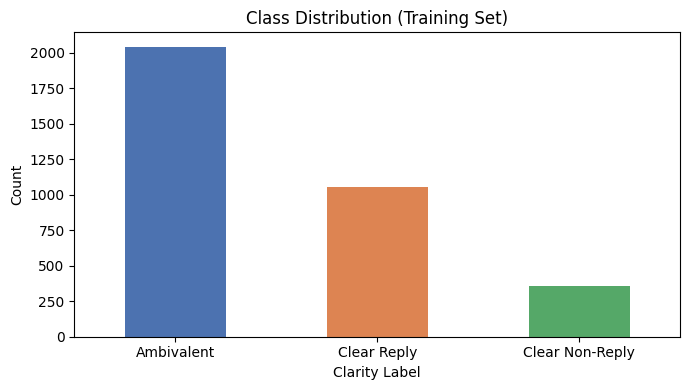

In [7]:
# Class distribution
print("=== Class Distribution (Training Set) ===")
print(df_train_full['clarity_label'].value_counts())
print()
print(df_train_full['clarity_label'].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
df_train_full['clarity_label'].value_counts().plot(
    kind='bar', ax=ax, color=['#4c72b0', '#dd8452', '#55a868']
)
ax.set_title('Class Distribution (Training Set)')
ax.set_xlabel('Clarity Label')
ax.set_ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('/kaggle/working/deberta_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

=== Question Length (characters) ===
count    3448.0
mean       84.5
std        51.9
min         3.0
25%        47.0
50%        74.0
75%       110.0
max       464.0
Name: question_len, dtype: float64

=== Answer Length (characters) ===
count     3448.0
mean      1663.3
std       1733.3
min          3.0
25%        309.0
50%       1155.5
75%       2495.0
max      12102.0
Name: answer_len, dtype: float64


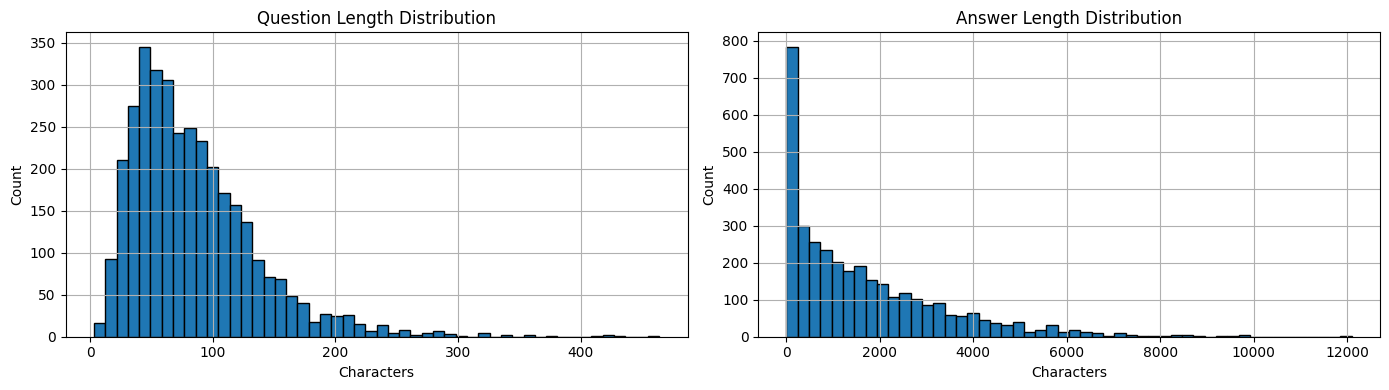

In [8]:
# Text length analysis
df_train_full['question_len'] = df_train_full['question'].astype(str).apply(len)
df_train_full['answer_len'] = df_train_full['interview_answer'].astype(str).apply(len)

print("=== Question Length (characters) ===")
print(df_train_full['question_len'].describe().round(1))
print("\n=== Answer Length (characters) ===")
print(df_train_full['answer_len'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_train_full['question_len'].hist(bins=50, ax=axes[0], edgecolor='black')
axes[0].set_title('Question Length Distribution')
axes[0].set_xlabel('Characters')
axes[0].set_ylabel('Count')
df_train_full['answer_len'].hist(bins=50, ax=axes[1], edgecolor='black')
axes[1].set_title('Answer Length Distribution')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.savefig('/kaggle/working/deberta_text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.3. Label Encoding

We map the clarity labels to integer IDs:
- `Clear Reply` → 0
- `Ambivalent` → 1
- `Clear Non-Reply` → 2

In [9]:
label2id = {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}
id2label = {v: k for k, v in label2id.items()}

df_train_full['label'] = df_train_full['clarity_label'].map(label2id)

print("Label mapping:", label2id)
print("\nLabel counts:")
print(df_train_full['label'].value_counts().sort_index().rename(id2label))

Label mapping: {'Clear Reply': 0, 'Ambivalent': 1, 'Clear Non-Reply': 2}

Label counts:
label
Clear Reply        1052
Ambivalent         2040
Clear Non-Reply     356
Name: count, dtype: int64


# 3. Tokenization & Input Formatting

## 3.1. Input Construction

Since each instance is a **question–answer pair**, we use DeBERTa's native sentence-pair input format:

**[CLS] question [SEP] answer [SEP]**

DeBERTa-v3 uses a SentencePiece vocabulary (128,100 tokens) instead of WordPiece, and is cased (no `do_lower_case`). The tokenizer automatically generates `token_type_ids` (0 for question tokens, 1 for answer tokens).

## 3.2. Loading the DeBERTa Tokenizer

In [10]:
MODEL_NAME = 'microsoft/deberta-v3-base'

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"DeBERTa-v3-base tokenizer loaded.")
print(f"Tokenizer class: {type(tokenizer).__name__}")
print(f"Vocabulary size: {tokenizer.vocab_size}")

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

DeBERTa-v3-base tokenizer loaded.
Tokenizer class: DebertaV2TokenizerFast
Vocabulary size: 128000


In [11]:
# DeBERTa uses [CLS] question [SEP] answer [SEP]
sample_q = str(df_train_full['question'].iloc[0])
sample_a = str(df_train_full['interview_answer'].iloc[0])

print("Question:", sample_q[:100], "...")
print("Answer:", sample_a[:100], "...")
print()

sample_enc = tokenizer(sample_q, sample_a, add_special_tokens=True)
decoded = tokenizer.decode(sample_enc['input_ids'][:40])
print("Decoded tokens (first 40 IDs):", decoded)

# DeBERTa-v3 DOES return token_type_ids (unlike DistilBERT)
if 'token_type_ids' in sample_enc:
    print("Token type IDs (first 40):", sample_enc['token_type_ids'][:40])
else:
    print("Note: No token_type_ids returned by this tokenizer.")

Question: How would you respond to the accusation that the United States is containing China while pushing for ...
Answer: Well, look, first of all, theI am sincere about getting the relationship right. And one of the thing ...



2026-04-26 13:31:30.937714: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777210291.126934      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777210291.178470      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777210291.606439      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777210291.606479      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777210291.606482      23 computation_placer.cc:177] computation placer alr

Decoded tokens (first 40 IDs): [CLS] How would you respond to the accusation that the United States is containing China while pushing for diplomatic talks?[SEP] Well, look, first of all, theI am sincere about getting the relationship right.
Token type IDs (first 40): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3.3. Choosing Maximum Sequence Length

DeBERTa-v3-base supports up to 512 tokens. We measure the token length distribution to choose `max_length`.

=== Token Length Statistics (question + answer) ===
  Min:    6
  Max:    2533
  Mean:   390.7
  Median: 286.5

  Fit in 128 tokens: 30.4%
  Fit in 256 tokens: 46.4%
  Fit in 384 tokens: 60.2%
  Fit in 512 tokens: 70.9%


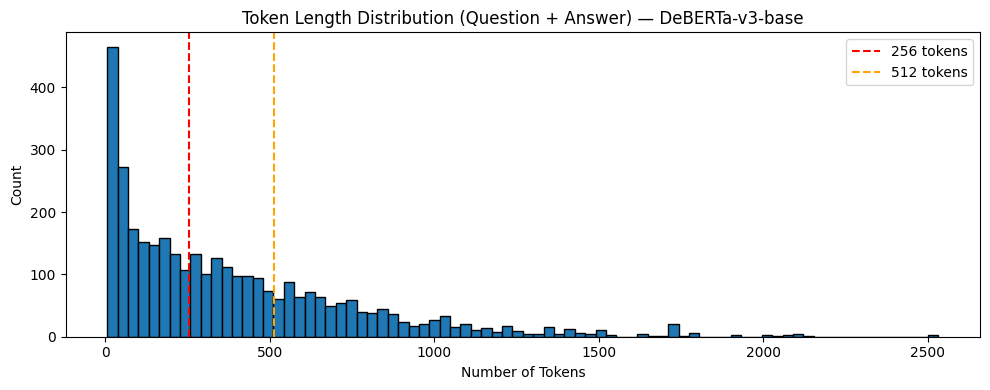

In [12]:
token_lengths = []

for _, row in df_train_full.iterrows():
    enc = tokenizer(str(row['question']), str(row['interview_answer']), add_special_tokens=True)
    token_lengths.append(len(enc['input_ids']))

token_lengths = np.array(token_lengths)

print("=== Token Length Statistics (question + answer) ===")
print(f"  Min:    {token_lengths.min()}")
print(f"  Max:    {token_lengths.max()}")
print(f"  Mean:   {token_lengths.mean():.1f}")
print(f"  Median: {np.median(token_lengths):.1f}")
print()
for ml in [128, 256, 384, 512]:
    pct = (token_lengths <= ml).mean() * 100
    print(f"  Fit in {ml} tokens: {pct:.1f}%")

plt.figure(figsize=(10, 4))
plt.hist(token_lengths, bins=80, edgecolor='black')
plt.axvline(x=256, color='red', linestyle='--', label='256 tokens')
plt.axvline(x=512, color='orange', linestyle='--', label='512 tokens')
plt.title('Token Length Distribution (Question + Answer) — DeBERTa-v3-base')
plt.xlabel('Number of Tokens')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/deberta_token_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 3.4. Tokenizing the Dataset

In [13]:
MAX_LEN = 512

def tokenize_pairs(questions, answers, tokenizer, max_len):
    """
    Tokenize question-answer pairs for DeBERTa sentence-pair input.
   
    """
    questions_list = [str(q) for q in questions]
    answers_list = [str(a) for a in answers]

    encoded = tokenizer(
        questions_list,
        answers_list,
        add_special_tokens=True,
        max_length=max_len,
        truncation=True,
        padding='max_length',
        return_attention_mask=True,
        return_token_type_ids=True,
        return_tensors='pt',
    )
    return encoded['input_ids'], encoded['attention_mask'], encoded['token_type_ids']

print(f"MAX_LEN = {MAX_LEN}")

MAX_LEN = 512


In [14]:

def extract_head_tail(text, max_words=350):
    words = str(text).split()
    if len(words) <= max_words:
        return text
    half = max_words // 2
    return " ".join(words[:half]) + " ... " + " ".join(words[-half:])

# Extract questions and labels
questions = df_train_full['question'].values
labels = df_train_full['label'].values

# Apply Head+Tail extraction to the raw answers
answers_raw = df_train_full['interview_answer'].values
answers = [extract_head_tail(ans) for ans in answers_raw]
# answers = df_train_full['interview_answer'].values

# Stratified 85/15 split 
train_questions, val_questions, train_answers, val_answers, train_labels, val_labels = train_test_split(
    questions, answers, labels,
    test_size=0.15,
    random_state=seed_val,
    stratify=labels,
)

print('{:>5,} training samples'.format(len(train_labels)))
print('{:>5,} validation samples'.format(len(val_labels)))
print()
print("Training label distribution:")
print(pd.Series(train_labels).value_counts().sort_index().rename(id2label))
print()
print("Validation label distribution:")
print(pd.Series(val_labels).value_counts().sort_index().rename(id2label))

2,930 training samples
  518 validation samples

Training label distribution:
Clear Reply         894
Ambivalent         1734
Clear Non-Reply     302
Name: count, dtype: int64

Validation label distribution:
Clear Reply        158
Ambivalent         306
Clear Non-Reply     54
Name: count, dtype: int64


In [15]:
print("Tokenizing training set...")
train_input_ids, train_attention_masks, train_token_type_ids = tokenize_pairs(
    train_questions, train_answers, tokenizer, MAX_LEN
)
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)

print("Tokenizing validation set...")
val_input_ids, val_attention_masks, val_token_type_ids = tokenize_pairs(
    val_questions, val_answers, tokenizer, MAX_LEN
)
val_labels_tensor = torch.tensor(val_labels, dtype=torch.long)

print("Done!")
print(f"  Training input shape:   {train_input_ids.shape}")
print(f"  Validation input shape: {val_input_ids.shape}")

Tokenizing training set...
Tokenizing validation set...
Done!
  Training input shape:   torch.Size([2930, 512])
  Validation input shape: torch.Size([518, 512])


In [16]:
# Verify tokenization structure 
idx = 0
decoded = tokenizer.decode(train_input_ids[idx], skip_special_tokens=False)
print("Label:", id2label[train_labels[idx]])
print("Decoded (first 300 chars):", decoded[:300])
print()
print("Token type IDs (first 30):", train_token_type_ids[idx][:30].tolist())

Label: Ambivalent
Decoded (first 300 chars): [CLS] Do you still think it was the right decision to intervene in this debate?[SEP] Well, first of all, let me repeat: This is a decision for the people of the United Kingdom to make. I'm not coming here to fix any votes. I'm not casting a vote myself. I'm offering my opinion. And in democracies, y

Token type IDs (first 30): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 3.5. Create DataLoaders

In [17]:
batch_size = 8

train_dataset = TensorDataset(
    train_input_ids, train_attention_masks, train_token_type_ids, train_labels_tensor
)
train_dataloader = DataLoader(
    train_dataset,
    sampler=RandomSampler(train_dataset),
    batch_size=batch_size,
)

val_dataset = TensorDataset(
    val_input_ids, val_attention_masks, val_token_type_ids, val_labels_tensor
)
validation_dataloader = DataLoader(
    val_dataset,
    sampler=SequentialSampler(val_dataset),
    batch_size=batch_size,
)

print(f"Batch size: {batch_size}")
print(f"Training batches:   {len(train_dataloader)}")
print(f"Validation batches: {len(validation_dataloader)}")

Batch size: 8
Training batches:   367
Validation batches: 65


# 4. Train Our Classification Model

## 4.1. DebertaV2ForSequenceClassification

We load the pretrained `microsoft/deberta-v3-base` model with a single linear classification layer on top for 3 output labels.

We also compute **class weights** (square-root inverse frequency) and use a weighted `CrossEntropyLoss` to handle the class imbalance.

In [18]:
config = AutoConfig.from_pretrained(MODEL_NAME)
config.num_labels = 3
config.classifier_dropout = 0.3

print("Model config summary:")
print(f"  Model type:               {config.model_type}")
print(f"  Hidden size:              {config.hidden_size}")
print(f"  Num hidden layers:        {config.num_hidden_layers}")
print(f"  Num attention heads:      {config.num_attention_heads}")
print(f"  Num labels:               {config.num_labels}")
print(f"  Classifier dropout:       {config.classifier_dropout}")

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    config=config,
)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

params = list(model.named_parameters())
print(f'\nThe DeBERTa model has {len(params)} different named parameters.\n')

print('==== Embedding Layer ====\n')
for p in params[0:5]:
    print("{:<65} {:>12}".format(p[0], str(tuple(p[1].size()))))

print('\n==== First Transformer ====\n')
for p in params[5:21]:
    print("{:<65} {:>12}".format(p[0], str(tuple(p[1].size()))))

print('\n==== Output Layer ====\n')
for p in params[-4:]:
    print("{:<65} {:>12}".format(p[0], str(tuple(p[1].size()))))

Model config summary:
  Model type:               deberta-v2
  Hidden size:              768
  Num hidden layers:        12
  Num attention heads:      12
  Num labels:               3
  Classifier dropout:       0.3


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/deberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Total parameters:     184,424,451
Trainable parameters: 184,424,451

The DeBERTa model has 202 different named parameters.

==== Embedding Layer ====

deberta.embeddings.word_embeddings.weight                         (128100, 768)
deberta.embeddings.LayerNorm.weight                                     (768,)
deberta.embeddings.LayerNorm.bias                                       (768,)
deberta.encoder.layer.0.attention.self.query_proj.weight            (768, 768)
deberta.encoder.layer.0.attention.self.query_proj.bias                  (768,)

==== First Transformer ====

deberta.encoder.layer.0.attention.self.key_proj.weight              (768, 768)
deberta.encoder.layer.0.attention.self.key_proj.bias                    (768,)
deberta.encoder.layer.0.attention.self.value_proj.weight            (768, 768)
deberta.encoder.layer.0.attention.self.value_proj.bias                  (768,)
deberta.encoder.layer.0.attention.output.dense.weight               (768, 768)
deberta.encoder.layer.0.att

In [19]:
class_counts = np.bincount(train_labels)
n_samples = len(train_labels)
n_classes = 3
class_weights = np.sqrt(n_samples / (n_classes * class_counts))
# Square-root inverse frequency weighting — softer than linear inverse frequency
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = CrossEntropyLoss(weight=class_weights_tensor, label_smoothing=0.1)

## 4.2. Optimizer & Learning Rate Scheduler

- **Batch size**: 8 (effective 32 with gradient accumulation × 4)
- **Learning rate (AdamW)**: 2e-5
- **Epochs**: 4
- **Warmup**: 20% of total steps, then linear decay
- **Weight decay**: 0.01 (excluding bias and LayerNorm parameters)

In [20]:
epochs = 4
learning_rate = 2e-5
accumulation_steps = 4

no_decay = ['bias', 'LayerNorm.weight', 'LayerNorm.bias']
optimizer_grouped_parameters = [
    {
        'params': [p for n, p in model.named_parameters()
                   if not any(nd in n for nd in no_decay)],
        'weight_decay': 0.01
    },
    {
        'params': [p for n, p in model.named_parameters()
                   if any(nd in n for nd in no_decay)],
        'weight_decay': 0.0
    }
]

optimizer = AdamW(optimizer_grouped_parameters, lr=learning_rate, eps=1e-8)

total_steps = (len(train_dataloader) // accumulation_steps) * epochs
warmup_steps = int(0.20* total_steps)  

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print(f"Epochs:              {epochs}")
print(f"LR:                  {learning_rate}")
print(f"Accumulation steps:  {accumulation_steps}")
print(f"Effective batch:     {batch_size * accumulation_steps}")
print(f"Total steps:         {total_steps}")
print(f"Warmup steps:        {warmup_steps} ({warmup_steps/total_steps:.1%})")
print(f"Weight decay:        0.01 (excluding bias/LayerNorm)")

Epochs:              4
LR:                  2e-05
Accumulation steps:  4
Effective batch:     32
Total steps:         364
Warmup steps:        72 (19.8%)
Weight decay:        0.01 (excluding bias/LayerNorm)


## 4.3. Training Loop

**Training:** Unpack data → GPU → zero gradients → forward pass → weighted loss → backward → gradient accumulation → clip gradients → optimizer step → scheduler step

**Validation:** Unpack data → GPU → forward pass (no gradients) → loss & metrics

We track F1-score (weighted and macro) in addition to accuracy and loss, as required by the assignment.

In [21]:
def format_time(elapsed):
    '''Takes a time in seconds and returns a string hh:mm:ss'''
    elapsed_rounded = int(round(elapsed))
    return str(datetime.timedelta(seconds=elapsed_rounded))

def flat_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)

In [22]:
training_stats = []
best_val_f1 = 0.0
best_val_loss = float('inf')
best_model_state = None
best_epoch = 0
total_t0 = time.time()

# Early stopping parameters
patience = 2  # Stop if val F1 doesn't improve for 2 epochs
patience_counter = 0

import torch, gc
torch.cuda.empty_cache()
gc.collect()

for epoch_i in range(0, epochs):

    # ========================================
    #               Training
    # ========================================
    print("")
    print('======== Epoch {:} / {:} ========'.format(epoch_i + 1, epochs))
    print('Training...')

    t0 = time.time()
    total_train_loss = 0
    model.train()
    optimizer.zero_grad()

    for step, batch in enumerate(train_dataloader):

        if step % 40 == 0 and not step == 0:
            elapsed = format_time(time.time() - t0)
            print('  Batch {:>5,}  of  {:>5,}.    Elapsed: {:}.'.format(
                step, len(train_dataloader), elapsed))

        b_input_ids      = batch[0].to(device)
        b_input_mask     = batch[1].to(device)
        b_token_type_ids = batch[2].to(device)
        b_labels         = batch[3].to(device)

        result = model(
            b_input_ids,
            token_type_ids=b_token_type_ids,
            attention_mask=b_input_mask,
            return_dict=True
        )

        logits = result.logits
        loss = loss_fn(logits, b_labels) / accumulation_steps
        total_train_loss += loss.item() * accumulation_steps  # Restore true loss for logging


        loss.backward()

        if (step + 1) % accumulation_steps == 0 or (step + 1) == len(train_dataloader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        # Free memory
        del b_input_ids, b_input_mask, b_token_type_ids, b_labels, logits, loss
        torch.cuda.empty_cache()

    avg_train_loss = total_train_loss / len(train_dataloader)
    training_time = format_time(time.time() - t0)

    print("")
    print("  Average training loss: {0:.4f}".format(avg_train_loss))
    print("  Training epoch took:   {:}".format(training_time))

    # ========================================
    #               Validation
    # ========================================
    print("")
    print("Running Validation...")

    t0 = time.time()
    model.eval()

    total_eval_accuracy = 0
    total_eval_loss = 0
    all_preds = []
    all_true = []

    for batch in validation_dataloader:

        b_input_ids      = batch[0].to(device)
        b_input_mask     = batch[1].to(device)
        b_token_type_ids = batch[2].to(device)
        b_labels         = batch[3].to(device)

        with torch.no_grad():
            result = model(
                b_input_ids,
                token_type_ids=b_token_type_ids,
                attention_mask=b_input_mask,
                return_dict=True
            )

        logits = result.logits
        loss = loss_fn(logits.float(), b_labels)
        total_eval_loss += loss.item()

        logits_np = logits.detach().cpu().numpy()
        label_ids = b_labels.to('cpu').numpy()

        total_eval_accuracy += flat_accuracy(logits_np, label_ids)
        all_preds.extend(np.argmax(logits_np, axis=1).flatten().tolist())
        all_true.extend(label_ids.flatten().tolist())

    avg_val_accuracy = total_eval_accuracy / len(validation_dataloader)
    avg_val_loss = total_eval_loss / len(validation_dataloader)
    val_f1 = f1_score(all_true, all_preds, average='weighted')
    val_macro_f1 = f1_score(all_true, all_preds, average='macro')
    validation_time = format_time(time.time() - t0)

    print("  Accuracy:        {0:.4f}".format(avg_val_accuracy))
    print("  Validation Loss: {0:.4f}".format(avg_val_loss))
    print("  F1 (weighted):   {0:.4f}".format(val_f1))
    print("  F1 (macro):      {0:.4f}".format(val_macro_f1))
    print("  Validation took: {:}".format(validation_time))

    # Save best model (by weighted F1)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        best_epoch = epoch_i + 1
        patience_counter = 0  # Reset patience
    else:
        patience_counter += 1  # Increment patience
    
        
    training_stats.append({
        'epoch': epoch_i + 1,
        'Training Loss': avg_train_loss,
        'Valid. Loss': avg_val_loss,
        'Valid. Accur.': avg_val_accuracy,
        'Valid. F1 (weighted)': val_f1,
        'Valid. F1 (macro)': val_macro_f1,
        'Training Time': training_time,
        'Validation Time': validation_time,
    })

    # Early stopping check
    if patience_counter >= patience:
        print(f"\n Early stopping triggered at epoch {epoch_i + 1}")
        print(f"   Best F1 was {best_val_f1:.4f} at epoch {best_epoch}")
        break

print("")
print("Training complete!")
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"\nRestored best model from epoch {best_epoch} (F1={best_val_f1:.4f})")
print("Total training took {:} (h:mm:ss)".format(format_time(time.time()-total_t0)))


======== Epoch 1 / 4 ========
Training...
  Batch    40  of    367.    Elapsed: 0:00:45.
  Batch    80  of    367.    Elapsed: 0:01:32.
  Batch   120  of    367.    Elapsed: 0:02:23.
  Batch   160  of    367.    Elapsed: 0:03:15.
  Batch   200  of    367.    Elapsed: 0:04:08.
  Batch   240  of    367.    Elapsed: 0:05:00.
  Batch   280  of    367.    Elapsed: 0:05:53.
  Batch   320  of    367.    Elapsed: 0:06:45.
  Batch   360  of    367.    Elapsed: 0:07:38.

  Average training loss: 1.0842
  Training epoch took:   0:07:46

Running Validation...
  Accuracy:        0.5942
  Validation Loss: 1.0586
  F1 (weighted):   0.4473
  F1 (macro):      0.2720
  Validation took: 0:00:28

======== Epoch 2 / 4 ========
Training...
  Batch    40  of    367.    Elapsed: 0:00:53.
  Batch    80  of    367.    Elapsed: 0:01:45.
  Batch   120  of    367.    Elapsed: 0:02:37.
  Batch   160  of    367.    Elapsed: 0:03:30.
  Batch   200  of    367.    Elapsed: 0:04:22.
  Batch   240  of    367.    Elapsed

# 5. Training Results

In [23]:
pd.options.display.precision = 4
df_stats = pd.DataFrame(data=training_stats)
df_stats = df_stats.set_index('epoch')
df_stats

,Training Loss,Valid. Loss,Valid. Accur.,Valid. F1 (weighted),Valid. F1 (macro),Training Time,Validation Time
epoch,,,,,,,
1,1.0842,1.0586,0.5942,0.4473,0.2720,0:07:46,0:00:28
2,1.0426,0.9897,0.6109,0.5000,0.4403,0:08:00,0:00:28
3,0.9636,0.9515,0.6417,0.6199,0.5854,0:07:58,0:00:28
4,0.9060,0.9401,0.6256,0.5654,0.5244,0:07:57,0:00:28


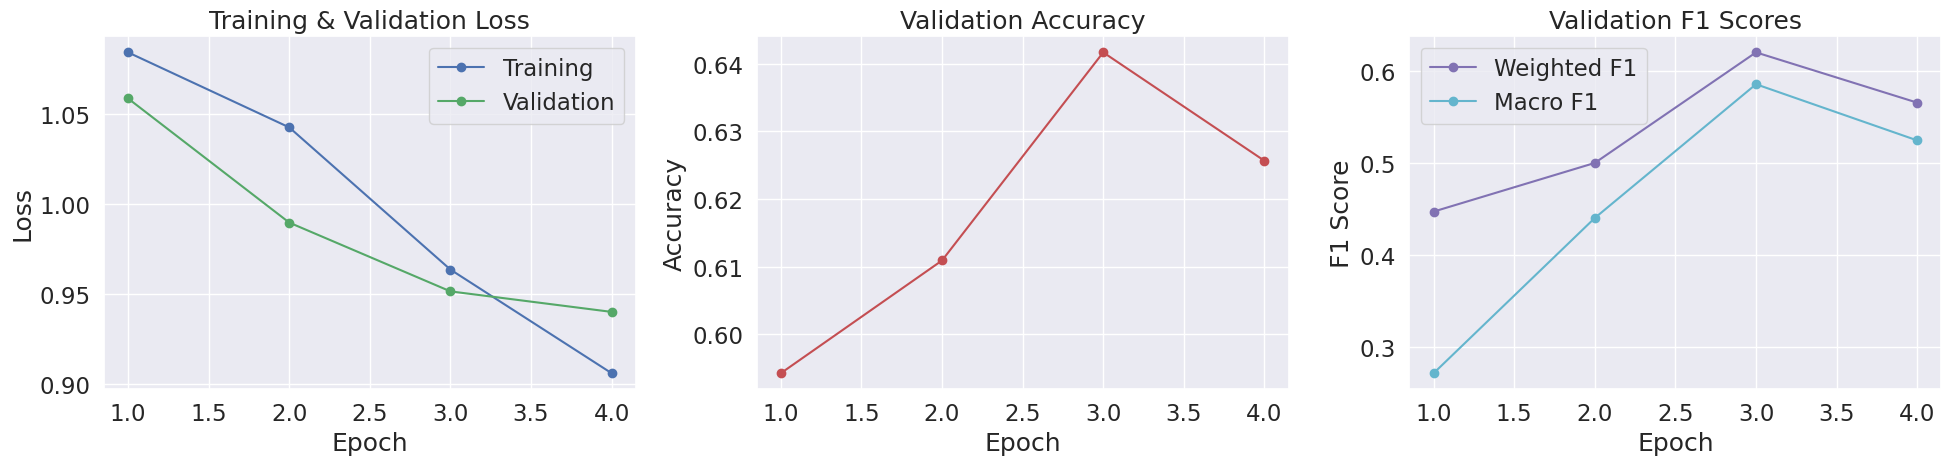

In [24]:
sns.set(style='darkgrid')
sns.set(font_scale=1.5)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(df_stats['Training Loss'], 'b-o', label="Training")
axes[0].plot(df_stats['Valid. Loss'], 'g-o', label="Validation")
axes[0].set_title("Training & Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(df_stats['Valid. Accur.'], 'r-o')
axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[2].plot(df_stats['Valid. F1 (weighted)'], 'm-o', label="Weighted F1")
axes[2].plot(df_stats['Valid. F1 (macro)'], 'c-o', label="Macro F1")
axes[2].set_title("Validation F1 Scores")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("F1 Score")
axes[2].legend()

plt.tight_layout()
plt.savefig('/kaggle/working/deberta_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# 6. Detailed Evaluation on Validation Set

In [25]:
model.eval()
all_preds = []
all_labels_eval = []

for batch in validation_dataloader:
    b_input_ids      = batch[0].to(device)
    b_input_mask     = batch[1].to(device)
    b_token_type_ids = batch[2].to(device)
    b_labels         = batch[3].to(device)

    with torch.no_grad():
        result = model(
            b_input_ids,
            token_type_ids=b_token_type_ids,
            attention_mask=b_input_mask,
            return_dict=True
        )

    logits = result.logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()
    all_preds.extend(np.argmax(logits, axis=1).flatten().tolist())
    all_labels_eval.extend(label_ids.flatten().tolist())

target_names = [id2label[i] for i in range(3)]

print("=== Classification Report ===\n")
print(classification_report(all_labels_eval, all_preds, target_names=target_names, digits=4))

print(f"Accuracy:          {accuracy_score(all_labels_eval, all_preds):.4f}")
print(f"F1 (weighted):     {f1_score(all_labels_eval, all_preds, average='weighted'):.4f}")
print(f"F1 (macro):        {f1_score(all_labels_eval, all_preds, average='macro'):.4f}")
print(f"Precision (macro): {precision_score(all_labels_eval, all_preds, average='macro'):.4f}")
print(f"Recall (macro):    {recall_score(all_labels_eval, all_preds, average='macro'):.4f}")

=== Classification Report ===

                 precision    recall  f1-score   support

    Clear Reply     0.5158    0.3101    0.3874       158
     Ambivalent     0.6776    0.8105    0.7381       306
Clear Non-Reply     0.6140    0.6481    0.6306        54

       accuracy                         0.6409       518
      macro avg     0.6025    0.5896    0.5854       518
   weighted avg     0.6216    0.6409    0.6199       518

Accuracy:          0.6409
F1 (weighted):     0.6199
F1 (macro):        0.5854
Precision (macro): 0.6025
Recall (macro):    0.5896


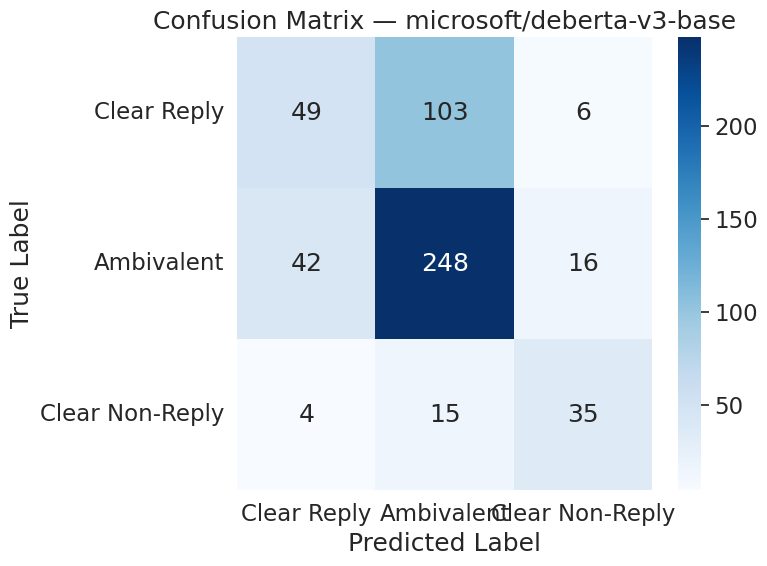

In [26]:
cm = confusion_matrix(all_labels_eval, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix — microsoft/deberta-v3-base')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('/kaggle/working/deberta_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# 7. Error Analysis

We examine misclassified examples to understand model failures.


In [27]:
val_results = pd.DataFrame({
    'question': val_questions,
    'answer': val_answers,
    'true_label': [id2label[l] for l in val_labels],
    'predicted_label': [id2label[p] for p in all_preds],
    'correct': [t == p for t, p in zip(all_labels_eval, all_preds)],
})

errors = val_results[~val_results['correct']].copy()
print(f"Total validation samples: {len(val_results)}")
print(f"Misclassified:            {len(errors)}")
print(f"Error rate:               {len(errors)/len(val_results):.2%}")
print()
print("=== Errors by True Label ===")
print(errors['true_label'].value_counts())
print()
print("=== Confusion Pairs (True -> Predicted) ===")
print(errors.groupby(['true_label', 'predicted_label']).size().sort_values(ascending=False))

Total validation samples: 518
Misclassified:            186
Error rate:               35.91%

=== Errors by True Label ===
true_label
Clear Reply        109
Ambivalent          58
Clear Non-Reply     19
Name: count, dtype: int64

=== Confusion Pairs (True -> Predicted) ===
true_label       predicted_label
Clear Reply      Ambivalent         103
Ambivalent       Clear Reply         42
                 Clear Non-Reply     16
Clear Non-Reply  Ambivalent          15
Clear Reply      Clear Non-Reply      6
Clear Non-Reply  Clear Reply          4
dtype: int64


In [28]:
print("=" * 80)
print("SAMPLE MISCLASSIFIED EXAMPLES")
print("=" * 80)

for i, (_, row) in enumerate(errors.head(5).iterrows()):
    print(f"\n--- Example {i+1} ---")
    print(f"True: {row['true_label']}  |  Predicted: {row['predicted_label']}")
    print(f"Question: {str(row['question'])[:250]}")
    print(f"Answer:   {str(row['answer'])[:400]}")
    print("-" * 80)

SAMPLE MISCLASSIFIED EXAMPLES

--- Example 1 ---
True: Ambivalent  |  Predicted: Clear Reply
Question:  Expressing concerns about exacerbating tensions and increasing violence.
Answer:   Well, it could also increase enthusiasm, and it could increase love and respect for our country. And that's why I'm going, because they did a fantastic job. As soon as I called and told them, Let's go, the whole problem stopped. That was—what?—6 days ago.Yes, Jeff [Jeff Mason, Reuters].
--------------------------------------------------------------------------------

--- Example 2 ---
True: Clear Reply  |  Predicted: Clear Non-Reply
Question:  Is ASEAN ready for the more advanced role in world affairs the U.S. would like to see it play?
Answer:   I have not--I've been out of town, so I'm just seeing the press reports. I have not had a full briefing on Israel's intentions and what they've communicated to our administration. But this kind of activity is never helpful when it comes to peace negotiations. 

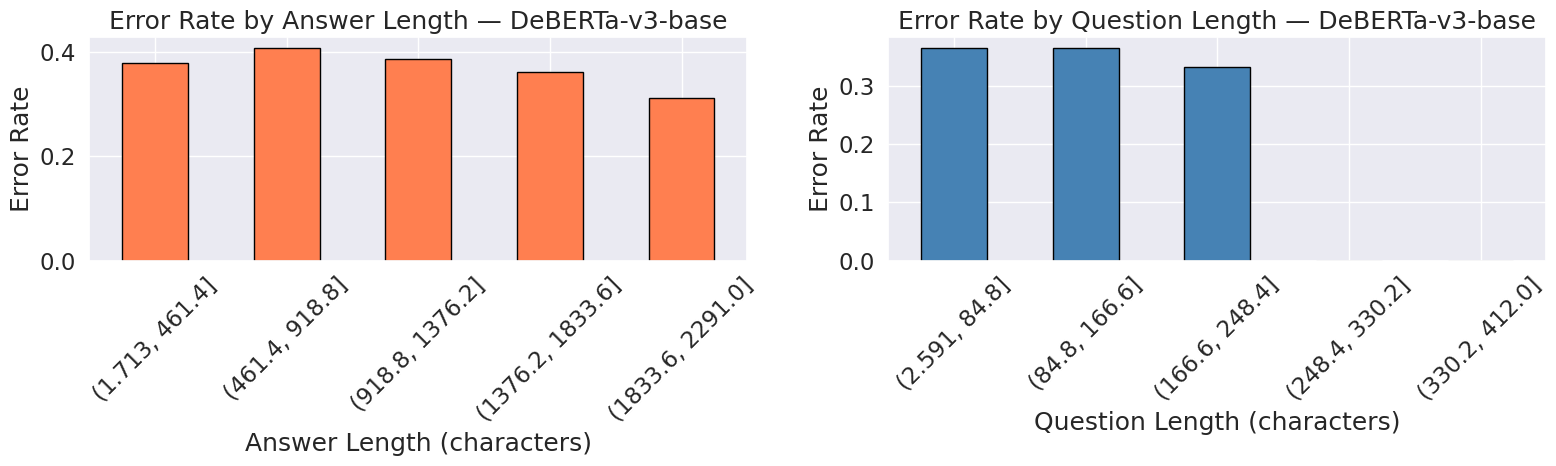

In [29]:
val_results['a_len'] = val_results['answer'].astype(str).apply(len)
val_results['q_len'] = val_results['question'].astype(str).apply(len)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

val_results['a_len_bin'] = pd.cut(val_results['a_len'], bins=5)
error_by_alen = val_results.groupby('a_len_bin', observed=True)['correct'].apply(lambda x: 1 - x.mean())
error_by_alen.plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Error Rate by Answer Length — DeBERTa-v3-base')
axes[0].set_xlabel('Answer Length (characters)')
axes[0].set_ylabel('Error Rate')
axes[0].tick_params(axis='x', rotation=45)

val_results['q_len_bin'] = pd.cut(val_results['q_len'], bins=5)
error_by_qlen = val_results.groupby('q_len_bin', observed=True)['correct'].apply(lambda x: 1 - x.mean())
error_by_qlen.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title('Error Rate by Question Length — DeBERTa-v3-base')
axes[1].set_xlabel('Question Length (characters)')
axes[1].set_ylabel('Error Rate')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('/kaggle/working/deberta_error_rate_by_length.png', dpi=150, bbox_inches='tight')
plt.show()

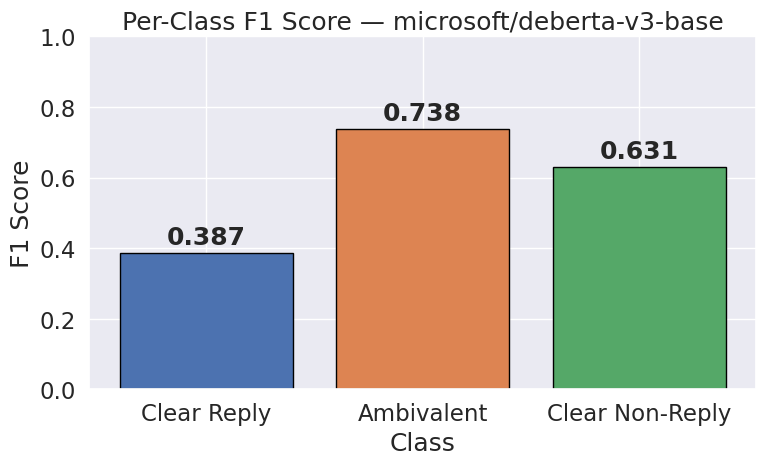

In [30]:
from sklearn.metrics import f1_score as f1_per_class

per_class_f1 = f1_per_class(all_labels_eval, all_preds, average=None, labels=[0, 1, 2])

plt.figure(figsize=(8, 5))
bars = plt.bar(target_names, per_class_f1,
               color=['#4c72b0', '#dd8452', '#55a868'], edgecolor='black')
for bar, val in zip(bars, per_class_f1):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
plt.title('Per-Class F1 Score — microsoft/deberta-v3-base')
plt.xlabel('Class')
plt.ylabel('F1 Score')
plt.ylim(0, 1.0)
plt.tight_layout()
plt.savefig('/kaggle/working/deberta_per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

# 8. Predictions on Test Set & Kaggle Submission

In [31]:
# Apply the same Head+Tail extraction to test set answers
test_questions_raw = df_test['question'].values
test_answers_raw = df_test['interview_answer'].values
test_answers = [extract_head_tail(ans) for ans in test_answers_raw]
# test_answers = df_test['interview_answer'].values
print(f"Test set size: {len(test_questions_raw)}")
print("Tokenizing test set...")

test_input_ids, test_attention_masks, test_token_type_ids = tokenize_pairs(
    test_questions_raw, test_answers, tokenizer, MAX_LEN
)

test_dataset = TensorDataset(test_input_ids, test_attention_masks, test_token_type_ids)
test_dataloader = DataLoader(
    test_dataset,
    sampler=SequentialSampler(test_dataset),
    batch_size=batch_size
)

print(f"Test batches: {len(test_dataloader)}")

Test set size: 308
Tokenizing test set...
Test batches: 39


In [32]:
print('Predicting labels for {:,} test samples...'.format(len(test_input_ids)))

model.eval()
test_predictions = []

for batch in test_dataloader:
    b_input_ids      = batch[0].to(device)
    b_input_mask     = batch[1].to(device)
    b_token_type_ids = batch[2].to(device)

    with torch.no_grad():
        result = model(
            b_input_ids,
            token_type_ids=b_token_type_ids,
            attention_mask=b_input_mask,
            return_dict=True
        )

    logits = result.logits.detach().cpu().numpy()
    test_predictions.extend(np.argmax(logits, axis=1).flatten().tolist())

print('    DONE.')
print(f"Generated {len(test_predictions)} predictions.")

Predicting labels for 308 test samples...
    DONE.
Generated 308 predictions.


In [33]:
test_pred_labels = [id2label[p] for p in test_predictions]

print("Test prediction distribution:")
print(pd.Series(test_pred_labels).value_counts())

Test prediction distribution:
Ambivalent         238
Clear Non-Reply     43
Clear Reply         27
Name: count, dtype: int64


In [34]:
submission = pd.DataFrame({
    'Id': df_test['index'].values,
    'Predicted': test_pred_labels,
})

submission.to_csv('/kaggle/working/submission_microsoft-deberta-v3-base.csv', index=False)
print("Saved: submission_microsoft-deberta-v3-base.csv")
print(f"Shape: {submission.shape}")
submission.head(10)

Saved: submission_microsoft-deberta-v3-base.csv
Shape: (308, 2)


,Id,Predicted
0,0,Ambivalent
1,1,Ambivalent
2,2,Ambivalent
3,3,Clear Non-Reply
4,4,Ambivalent
5,5,Ambivalent
6,6,Ambivalent
7,7,Ambivalent
8,8,Ambivalent
9,9,Ambivalent


# Summary

| Setting | Value |
|---|---|
| **Model** | `microsoft/deberta-v3-base` (~184M params, L=12, H=768, A=12) |
| **Tokenizer** | SentencePiece (DebertaV2Tokenizer) — cased |
| **Input format** | `[CLS] question [SEP] answer [SEP]` with `token_type_ids` |
| **MAX_LEN** | 512 |
| **Batch size** | 8 (physical) → 32 (effective with accumulation_steps=4) |
| **Learning rate** | 2e-5 |
| **Scheduler** | Linear warmup (20%) + linear decay |
| **Epochs** | 4 |
| **Gradient clipping** | max_norm = 1.0 |
| **Loss** | Weighted CrossEntropyLoss (square-root inverse frequency) + label_smoothing=0.1 |
| **Weight decay** | 0.01 (excluding bias/LayerNorm) |
| **Train/Val split** | 85/15 stratified |
| **Answer truncation** | Head+Tail (first 175 + last 175 words) |
| **Seed** | 42 |